# 02 · Coğrafi Analiz: Müşteriler, Satıcılar ve Teslimat Haritası

Bu notebook, `olist_geolocation_dataset.csv` dosyasındaki posta kodu koordinatlarını kullanarak
siparişleri Brezilya haritası üzerine yerleştirir.

**Sorular**
1. Müşteriler ve satıcılar ülke genelinde nasıl dağılıyor?
2. Teslimat süresi ve müşteri puanı bölgeden bölgeye nasıl değişiyor?
3. Satıcı ile müşteri arasındaki mesafe teslimat süresini, gecikmeyi ve kargo ücretini ne kadar etkiliyor?
4. Siparişler en çok hangi eyaletler arasında akıyor?

Harita altlığı (shapefile) kullanılmadı: ~100 bin siparişin koordinatları Brezilya'nın şeklini kendiliğinden çiziyor.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

import ortak
from ortak import MAVI, ORTA_GRI, SOLUK, YAZI, YUZEY, YUZDE, kaydet, sayi

ortak.stil_uygula()
t = ortak.tablolari_yukle()
df = ortak.siparis_tablosu(t)
koord = ortak.koordinatlar()
print(f"Teslim edilmiş sipariş: {sayi(len(df))} | koordinatı bilinen posta kodu öneki: {sayi(len(koord))}")

Teslim edilmiş sipariş: 96.203 | koordinatı bilinen posta kodu öneki: 19.010


## 1. Koordinatların hazırlanması

Konum tablosunda aynı posta kodu önekine ait çok sayıda nokta var (1 milyon satır, ~19 bin önek).
Her önek için **medyan** enlem/boylam alındı, Brezilya sınırları dışına düşen 42 hatalı nokta atıldı.
Böylece her müşteri ve satıcı, posta kodu bölgesinin merkezine yerleşti.

In [2]:
df = df.join(koord, on="customer_zip_code_prefix")
df["mesafe_km"] = df["order_id"].map(ortak.siparis_mesafesi(t, df, koord))

saticilar = t["saticilar"].join(koord, on="seller_zip_code_prefix")
satici_kalem = (t["kalemler"][t["kalemler"]["order_id"].isin(df["order_id"])]
                .merge(saticilar, on="seller_id"))

print(f"Koordinatı bulunan sipariş: %{sayi(df['lat'].notna().mean() * 100, 1)}")
print(f"Koordinatı bulunan satıcı: %{sayi(saticilar['lat'].notna().mean() * 100, 1)}")
print(f"Mesafesi hesaplanan sipariş: %{sayi(df['mesafe_km'].notna().mean() * 100, 1)}")

Koordinatı bulunan sipariş: %99,7
Koordinatı bulunan satıcı: %99,8
Mesafesi hesaplanan sipariş: %99,5


In [3]:
KAPSAM = (-74, -34, -34, 5.5)  # boylam min/max, enlem min/max


def harita(ax, baslik):
    ax.set_xlim(KAPSAM[:2])
    ax.set_ylim(KAPSAM[2:])
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(baslik)


def renk_cubugu(fig, hb, ax, etiket):
    cb = fig.colorbar(hb, ax=ax, shrink=0.6, pad=0.01)
    cb.set_label(etiket, color=YAZI)
    cb.outline.set_visible(False)
    cb.ax.tick_params(colors=SOLUK)
    return cb

## 2. Müşteri ve satıcı yoğunluğu

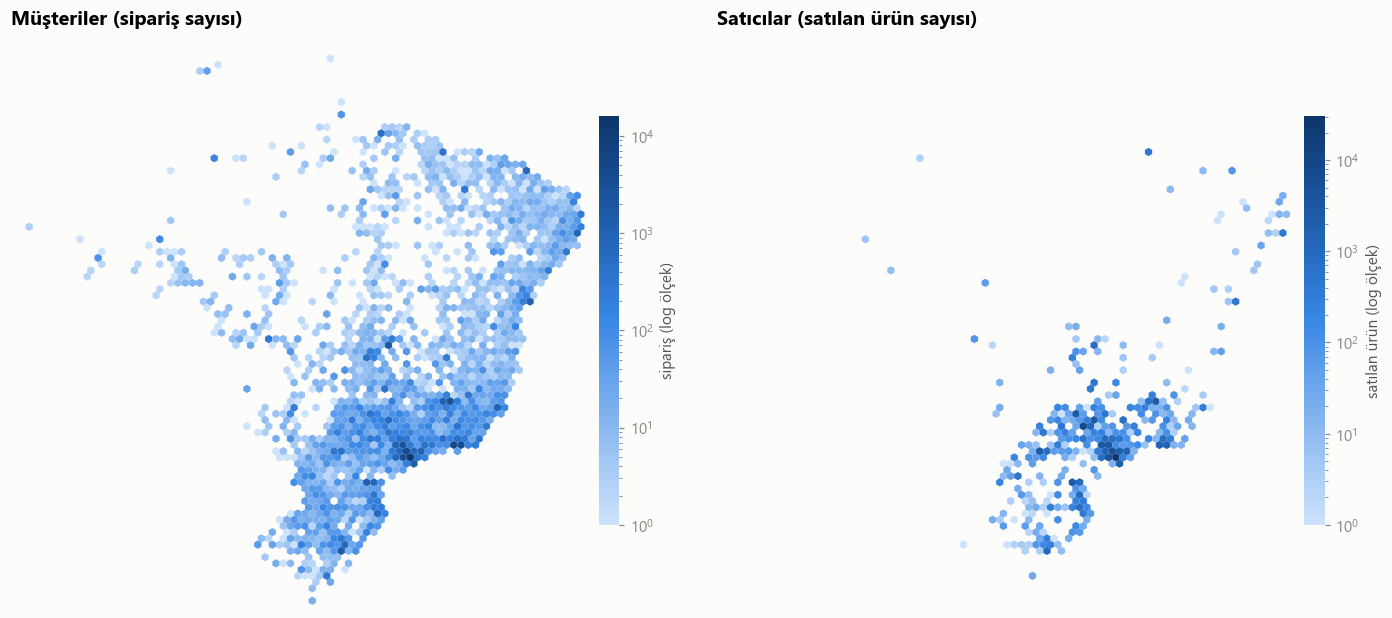

Güneydoğu bölgesinin (SP, RJ, MG, ES) payı — siparişler: %68,6, satılan ürünler: %83,7


In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.5))
m = df.dropna(subset=["lat"])
hb1 = ax1.hexbin(m["lng"], m["lat"], gridsize=80, bins="log", mincnt=1, extent=KAPSAM,
                 cmap=ortak.MAVI_RAMPA, linewidths=0)
harita(ax1, "Müşteriler (sipariş sayısı)")
renk_cubugu(fig, hb1, ax1, "sipariş (log ölçek)")

s = satici_kalem.dropna(subset=["lat"])
hb2 = ax2.hexbin(s["lng"], s["lat"], gridsize=80, bins="log", mincnt=1, extent=KAPSAM,
                 cmap=ortak.MAVI_RAMPA, linewidths=0)
harita(ax2, "Satıcılar (satılan ürün sayısı)")
renk_cubugu(fig, hb2, ax2, "satılan ürün (log ölçek)")
fig.tight_layout()
kaydet(fig, "geo_01_yogunluk")
plt.show()

guneydogu = ["SP", "RJ", "MG", "ES"]
print(f"Güneydoğu bölgesinin (SP, RJ, MG, ES) payı — siparişler: "
      f"%{sayi(df['customer_state'].isin(guneydogu).mean() * 100, 1)}, "
      f"satılan ürünler: %{sayi(satici_kalem['seller_state'].isin(guneydogu).mean() * 100, 1)}")

Müşteriler kıyı şeridi boyunca, özellikle güneydoğuda yoğunlaşsa da ülkenin her yerine yayılmış durumda.
Satıcılar ise neredeyse tamamen **São Paulo çevresinde** toplanmış. Kuzey ve kuzeydoğudaki müşteriler ürünlerini binlerce kilometre öteden alıyor.

## 3. Teslimat süresi ve müşteri puanı haritaları

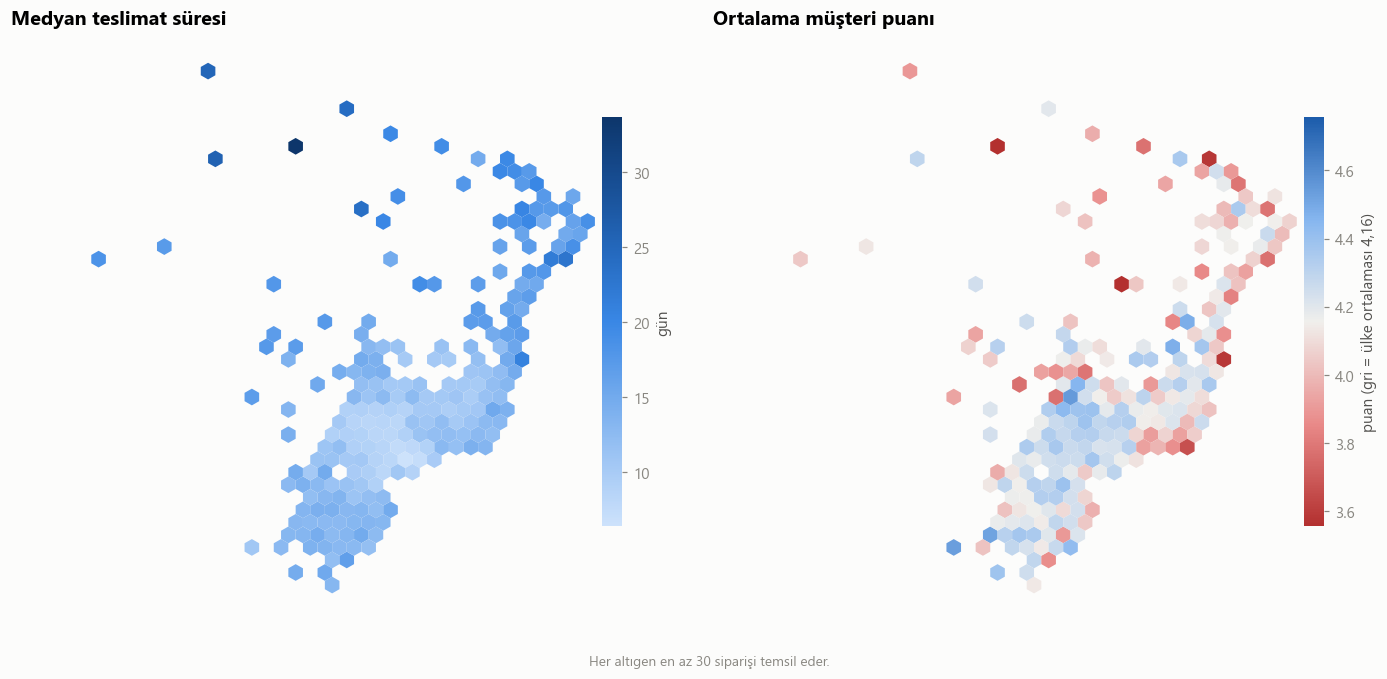

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.5))
hb1 = ax1.hexbin(m["lng"], m["lat"], C=m["teslim_suresi"], reduce_C_function=np.median,
                 gridsize=40, mincnt=30, extent=KAPSAM, cmap=ortak.MAVI_RAMPA, linewidths=0)
harita(ax1, "Medyan teslimat süresi")
renk_cubugu(fig, hb1, ax1, "gün")

puanli = m.dropna(subset=["review_score"])
ort = puanli["review_score"].mean()
hb2 = ax2.hexbin(puanli["lng"], puanli["lat"], C=puanli["review_score"], reduce_C_function=np.mean,
                 gridsize=40, mincnt=30, extent=KAPSAM, cmap=ortak.AYRISAN, linewidths=0,
                 norm=TwoSlopeNorm(vcenter=ort, vmin=ort - 0.6, vmax=ort + 0.6))
harita(ax2, "Ortalama müşteri puanı")
cb = renk_cubugu(fig, hb2, ax2, f"puan (gri = ülke ortalaması {sayi(ort, 2)})")
fig.text(0.5, 0.02, "Her altıgen en az 30 siparişi temsil eder.", ha="center", color=SOLUK, fontsize=9)
fig.tight_layout()
kaydet(fig, "geo_02_teslimat_puan")
plt.show()

İki harita birbirinin aynası gibi: teslimatın uzun sürdüğü kuzey ve kuzeydoğuda puanlar ülke ortalamasının altına iniyor (kırmızı).
Güney ve güneydoğuda ise teslimat hızlı, puanlar ortalamanın üstünde (mavi).
Dikkat çekici bir istisna **Rio de Janeiro**. Şehir, satıcıların toplandığı São Paulo'ya yalnızca ~360 km uzakta olmasına rağmen haritada kırmızı görünüyor (Bölüm 6'daki şehir tablosuna bakın).

## 4. Satıcı–müşteri mesafesinin etkisi

In [6]:
sinirlar = [0, 100, 250, 500, 1000, 1500, 2000, np.inf]
etiketler = ["0–100", "100–250", "250–500", "500–1000", "1000–1500", "1500–2000", "2000+"]
mesafe = (df.dropna(subset=["mesafe_km"])
          .assign(mesafe_grubu=lambda t: pd.cut(t["mesafe_km"], sinirlar, labels=etiketler, include_lowest=True))
          .groupby("mesafe_grubu", observed=True)
          .agg(siparis=("order_id", "count"), medyan_teslim_gun=("teslim_suresi", "median"),
               gec_oran=("gec", "mean"), ort_kargo=("kargo_ucreti", "mean"), ort_puan=("review_score", "mean")))
mesafe["siparis_payi"] = mesafe["siparis"] / mesafe["siparis"].sum()
print(f"Medyan satıcı–müşteri mesafesi: {sayi(df['mesafe_km'].median())} km")
print(f"Mesafe ile teslimat süresi arasındaki sıra korelasyonu (Spearman): "
      f"{sayi(df['mesafe_km'].corr(df['teslim_suresi'], method='spearman'), 2)}")
mesafe

Medyan satıcı–müşteri mesafesi: 436 km


Mesafe ile teslimat süresi arasındaki sıra korelasyonu (Spearman): 0,54


,siparis,medyan_teslim_gun,gec_oran,ort_kargo,ort_puan,siparis_payi
mesafe_grubu,,,,,,
0–100,17752,5.08,0.04,13.32,4.28,0.19
100–250,9350,7.85,0.05,18.04,4.29,0.10
250–500,27505,10.03,0.07,21.96,4.15,0.29
500–1000,25773,12.12,0.07,24.22,4.11,0.27
1000–1500,6586,14.88,0.09,29.93,4.05,0.07
1500–2000,3156,16.86,0.11,40.01,4.05,0.03
2000+,5604,18.23,0.12,39.92,3.97,0.06


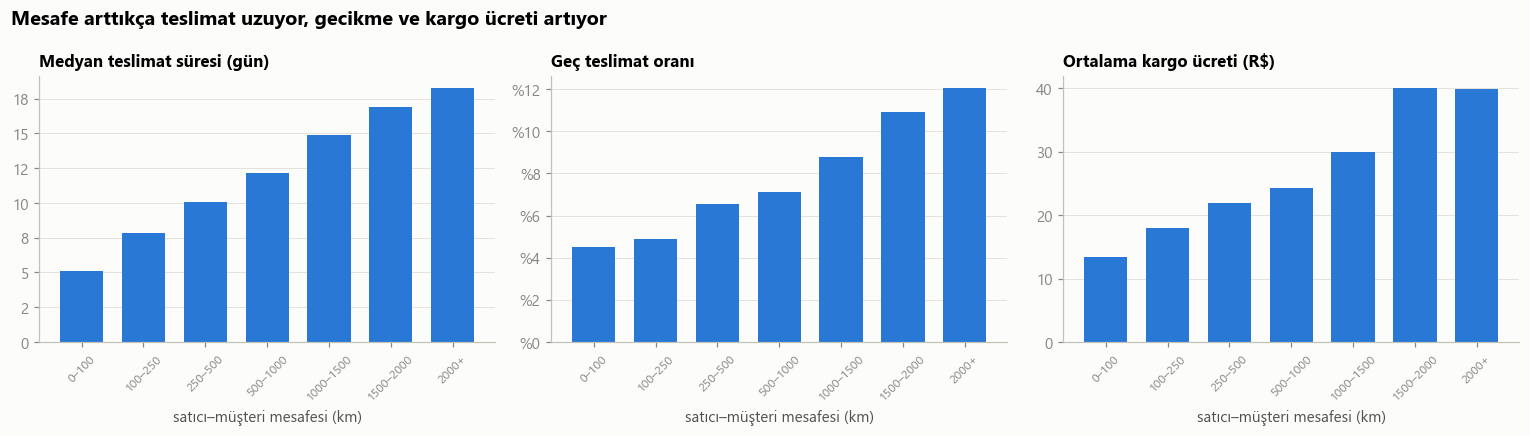

In [7]:
paneller = [("medyan_teslim_gun", "Medyan teslimat süresi (gün)", None),
            ("gec_oran", "Geç teslimat oranı", YUZDE),
            ("ort_kargo", "Ortalama kargo ücreti (R$)", None)]
fig, eksenler = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, (sutun, baslik, bicim) in zip(eksenler, paneller):
    degerler = mesafe[sutun] * (100 if bicim else 1)
    ax.bar(mesafe.index.astype(str), degerler, color=MAVI, width=0.7)
    ax.set_title(baslik, fontsize=11)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.yaxis.set_major_formatter(bicim or mtick.FuncFormatter(lambda v, _: sayi(v)))
    ax.set_xlabel("satıcı–müşteri mesafesi (km)")
fig.suptitle("Mesafe arttıkça teslimat uzuyor, gecikme ve kargo ücreti artıyor", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
kaydet(fig, "geo_03_mesafe")
plt.show()

## 5. Eyaletler arası sipariş akışı

Satıcı ve müşterinin aynı eyalette olduğu siparişler: %36,0


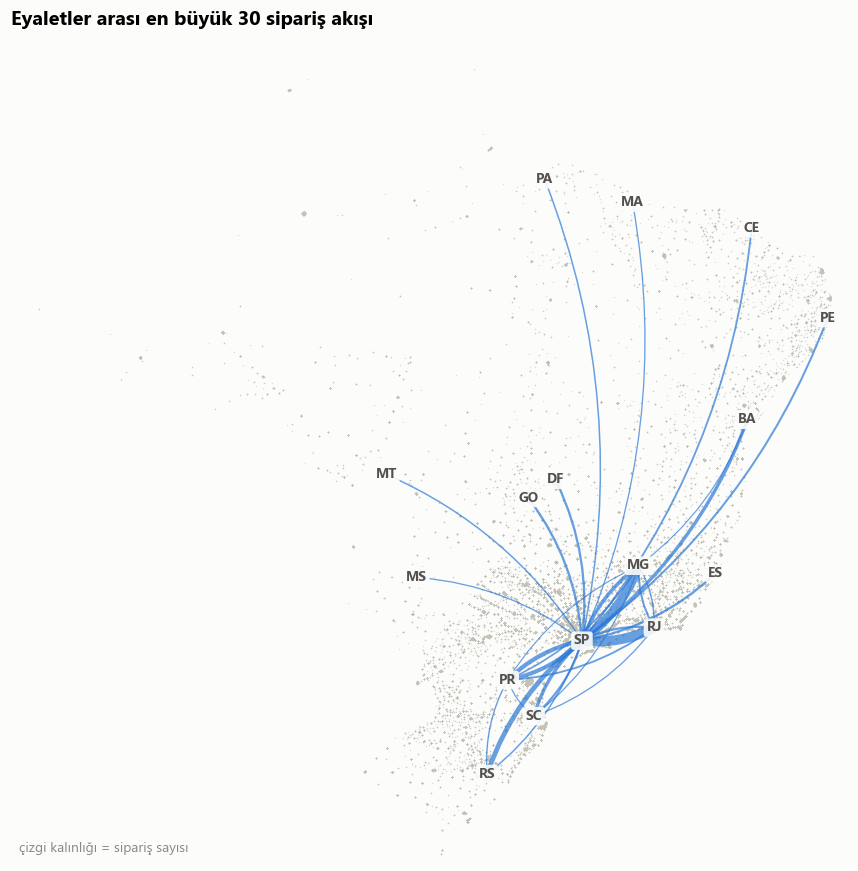

tüm siparişlerdeki payı (%)
seller_state customer_state                             
SP           RJ                                     8.50
             MG                                     7.70
             RS                                     3.70
             PR                                     3.20
PR           SP                                     3.00
MG           SP                                     2.60
SP           SC                                     2.40
             BA                                     2.40
             ES                                     1.50
             GO                                     1.50

In [8]:
akis_df = df.merge(satici_kalem.sort_values("price", ascending=False)
                   .drop_duplicates("order_id")[["order_id", "seller_state"]], on="order_id")
ayni = (akis_df["seller_state"] == akis_df["customer_state"]).mean()
print(f"Satıcı ve müşterinin aynı eyalette olduğu siparişler: %{sayi(ayni * 100, 1)}")

merkez = df.groupby("customer_state")[["lat", "lng"]].median()
akis = (akis_df[akis_df["seller_state"] != akis_df["customer_state"]]
        .groupby(["seller_state", "customer_state"]).size().sort_values(ascending=False))
ilk = akis.head(30)

fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(m["lng"], m["lat"], s=1, color=ORTA_GRI, alpha=0.5, linewidths=0)
for (kaynak, hedef), n in ilk.items():
    x0, y0 = merkez.loc[kaynak, ["lng", "lat"]]
    x1, y1 = merkez.loc[hedef, ["lng", "lat"]]
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-", color=MAVI, alpha=0.7, lw=0.5 + n / ilk.max() * 6,
                                connectionstyle="arc3,rad=0.15"))
for kod in set(ilk.index.get_level_values(0)) | set(ilk.index.get_level_values(1)):
    x, y = merkez.loc[kod, ["lng", "lat"]]
    ax.text(x, y, kod, fontsize=9, color=YAZI, ha="center", va="center", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc=YUZEY, ec="none", alpha=0.9))
harita(ax, "Eyaletler arası en büyük 30 sipariş akışı")
ax.text(0.01, 0.01, "çizgi kalınlığı = sipariş sayısı", transform=ax.transAxes, color=SOLUK, fontsize=9)
fig.tight_layout()
kaydet(fig, "geo_04_akis")
plt.show()

(akis.head(10) / len(akis_df) * 100).round(1).rename("tüm siparişlerdeki payı (%)").to_frame()

In [9]:
akis_df["rota"] = np.where(akis_df["seller_state"] == akis_df["customer_state"], "Aynı eyalet", "Farklı eyalet")
akis_df.groupby("rota").agg(
    siparis=("order_id", "count"), medyan_teslim_gun=("teslim_suresi", "median"),
    gec_oran=("gec", "mean"), ort_kargo=("kargo_ucreti", "mean"), ort_puan=("review_score", "mean"))

,siparis,medyan_teslim_gun,gec_oran,ort_kargo,ort_puan
rota,,,,,
Aynı eyalet,34603,6.52,0.05,15.44,4.26
Farklı eyalet,61600,12.78,0.08,26.91,4.10


In [10]:
sehir = (df.groupby("customer_city")
         .agg(siparis=("order_id", "count"), medyan_teslim_gun=("teslim_suresi", "median"),
              gec_oran=("gec", "mean"), ort_puan=("review_score", "mean"), medyan_mesafe_km=("mesafe_km", "median"))
         .sort_values("siparis", ascending=False).head(8))
sehir

,siparis,medyan_teslim_gun,gec_oran,ort_puan,medyan_mesafe_km
customer_city,,,,,
sao paulo,15014,6.52,0.05,4.23,96.40
rio de janeiro,6574,11.74,0.11,4.00,365.67
belo horizonte,2687,9.33,0.05,4.17,491.33
brasilia,2065,11.36,0.06,4.13,866.94
curitiba,1483,8.95,0.04,4.26,351.23
campinas,1400,8.05,0.09,4.15,102.57
porto alegre,1339,13.16,0.10,4.06,859.06
salvador,1188,17.17,0.15,3.80,"1,453.60"


## 6. Bulgular

| # | Bulgu |
|---|---|
| 1 | Güneydoğu (SP, RJ, MG, ES), siparişlerin **%69**'unu ama satılan ürünlerin **%84**'ünü oluşturuyor. Satış tarafı alış tarafından çok daha yoğunlaşmış. |
| 2 | Medyan satıcı–müşteri mesafesi **436 km**. Siparişlerin yalnızca **%36**'sında satıcı ve müşteri aynı eyalette. |
| 3 | Mesafe ile teslimat süresi arasında güçlü bir ilişki var (Spearman **0,54**). 100 km'nin altında medyan teslimat **5 gün**, 2.000 km'nin üstünde **18 gün**. Aynı aralıklarda geç teslimat oranı %4,5'ten %12'ye, ortalama kargo ücreti ise 13 R$'den 40 R$'ye çıkıyor. |
| 4 | Aynı eyalet içindeki siparişler, eyaletler arası siparişlere göre yarı sürede ve yarı kargo ücretiyle teslim ediliyor (6,5 güne karşı 12,8 gün; 15 R$'ye karşı 27 R$). |
| 5 | En büyük akışlar **SP → RJ** (tüm siparişlerin %8,5'i) ve **SP → MG** (%7,7). |
| 6 | **Rio de Janeiro şehri mesafeyle açıklanamayan bir sorun barındırıyor:** medyan teslimat 11,7 gün, geç teslimat %11, ortalama puan 4,00. São Paulo şehrinde bu değerler 6,5 gün, %5 ve 4,23. |

**Öneriler**
- Rio de Janeiro'da son kilometre teslimatı ayrıca incelenmeli (kargo firması performansı, dağıtım merkezi kapasitesi). Mesafe kısa olduğu için hızlı kazanım sağlayabilecek bir bölge.
- Kuzeydoğuya (BA, PE, CE) bölgesel bir depo kurmak veya bu bölgeden satıcı kazanmak, en uzun teslimat sürelerini ve en yüksek kargo ücretlerini birlikte düşürür.
- Tahmini teslim tarihi mesafeye göre hesaplanmalı: 2.000 km'nin üzerindeki siparişlerde geç teslimat oranı, 100 km'nin altındakilerin ~2,7 katı.